# Tugas Association Rule — Online Retail

**Muhammad Irzam Hafis Fabiansyah — 5054251024**

Tujuan: menemukan pola pembelian produk (aturan asosiasi) pada dataset *Online Retail* (UCI) menggunakan algoritma **FP-Growth**, lalu mengevaluasinya dengan **support**, **confidence**, dan **lift**.

## 1. Import Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import fpgrowth, association_rules

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_excel("../scratchpad/week5/data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. Eksplorasi dan Pembersihan Data

Kolom yang relevan untuk association rule: **`InvoiceNo`** (identitas transaksi/keranjang) dan **`Description`** (nama produk/item). `Quantity` dipakai untuk menyaring baris tidak valid.

In [5]:
print("Missing value per kolom:")
print(df.isna().sum())
print("\nInvoice dibatalkan (diawali 'C'):", df["InvoiceNo"].astype(str).str.startswith("C").sum(), "baris")
print("Quantity <= 0:", (df["Quantity"] <= 0).sum(), "baris")

Missing value per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Invoice dibatalkan (diawali 'C'): 9288 baris
Quantity <= 0: 10624 baris


In [6]:
def ringkas(d):
    return {"baris": len(d), "invoice unik": d["InvoiceNo"].nunique(), "produk unik": d["Description"].nunique()}

log = [("Data awal", ringkas(df))]

d = df.dropna(subset=["Description"])
log.append(("Hapus Description kosong", ringkas(d)))

d = d[~d["InvoiceNo"].astype(str).str.startswith("C")]
log.append(("Hapus invoice dibatalkan ('C')", ringkas(d)))

d = d[d["Quantity"] > 0]
log.append(("Hapus Quantity <= 0", ringkas(d)))

# Rapikan teks deskripsi (spasi berlebih) agar produk yang sama tidak terpecah
d = d.assign(Description=d["Description"].str.strip())
log.append(("Rapikan spasi Description", ringkas(d)))

pd.DataFrame({k: v for k, v in log}).T

,baris,invoice unik,produk unik
Data awal,541909,25900,4223
Hapus Description kosong,540455,24446,4223
Hapus invoice dibatalkan ('C'),531167,20610,4207
Hapus Quantity <= 0,530693,20136,4077
Rapikan spasi Description,530693,20136,4065


Beberapa baris `Description` bukan produk melainkan biaya/layanan (mis. `POSTAGE`, `Manual`, `AMAZON FEE`). Item seperti ini tidak informatif untuk pola belanja produk, sehingga dibuang sebagai langkah tambahan.

In [7]:
non_produk = ["POST", "DOT", "M", "D", "S", "B", "CRUK", "C2", "BANK CHARGES", "AMAZONFEE", "PADS"]
mask = d["StockCode"].astype(str).isin(non_produk)
print("Baris non-produk yang dibuang:", mask.sum())
print(d[mask]["Description"].value_counts().head(10))
clean = d[~mask].copy()
log.append(("Hapus item non-produk (postage, fee, dll)", ringkas(clean)))
ringkasan = pd.DataFrame({k: v for k, v in log}).T
ringkasan

Baris non-produk yang dibuang: 2325
Description
POSTAGE                       1126
DOTCOM POSTAGE                 708
Manual                         327
CARRIAGE                       141
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       4
Adjust bad debt                  3
AMAZON FEE                       2
SAMPLES                          2
Name: count, dtype: int64


,baris,invoice unik,produk unik
Data awal,541909,25900,4223
Hapus Description kosong,540455,24446,4223
Hapus invoice dibatalkan ('C'),531167,20610,4207
Hapus Quantity <= 0,530693,20136,4077
Rapikan spasi Description,530693,20136,4065
"Hapus item non-produk (postage, fee, dll)",528368,19955,4057


In [8]:
print(f"Sebelum: {len(df):,} baris, {df['InvoiceNo'].nunique():,} invoice")
print(f"Sesudah: {len(clean):,} baris, {clean['InvoiceNo'].nunique():,} invoice")

Sebelum: 541,909 baris, 25,900 invoice
Sesudah: 528,368 baris, 19,955 invoice


### Eksplorasi singkat data bersih

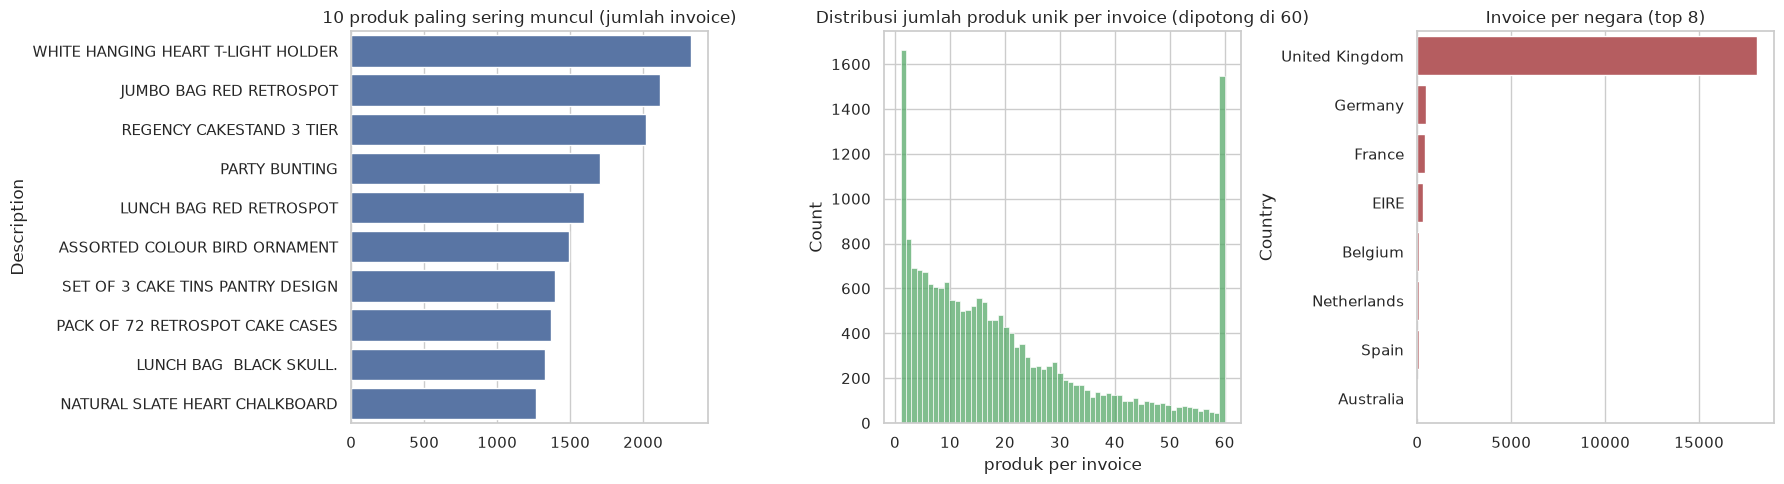

count    19955.000000
mean        25.937058
std         46.829932
min          1.000000
25%          6.000000
50%         15.000000
75%         29.000000
max       1107.000000
Name: Description, dtype: float64


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

top = clean["Description"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, ax=ax[0], color="#4C72B0")
ax[0].set_title("10 produk paling sering muncul (jumlah invoice)")

items_per_inv = clean.groupby("InvoiceNo")["Description"].nunique()
sns.histplot(items_per_inv.clip(upper=60), bins=60, ax=ax[1], color="#55A868")
ax[1].set_title("Distribusi jumlah produk unik per invoice (dipotong di 60)")
ax[1].set_xlabel("produk per invoice")

neg = clean.groupby("Country")["InvoiceNo"].nunique().sort_values(ascending=False).head(8)
sns.barplot(x=neg.values, y=neg.index, ax=ax[2], color="#C44E52")
ax[2].set_title("Invoice per negara (top 8)")
plt.tight_layout(); plt.show()
print(items_per_inv.describe())

## 3. Persiapan Data untuk Association Rule

Setiap **invoice = satu transaksi**, berisi daftar produk unik yang dibeli. Data diubah ke bentuk one-hot (basket): baris = invoice, kolom = produk, nilai `True` bila produk ada di invoice tersebut (kuantitas tidak dipakai, hanya ada/tidaknya).

In [10]:
transaksi = clean.groupby("InvoiceNo")["Description"].apply(lambda s: sorted(set(s)))
print("Contoh 3 transaksi:")
for inv, items in transaksi.head(3).items():
    print(inv, "->", items[:5], "...")
print("Jumlah transaksi:", len(transaksi))

Contoh 3 transaksi:
536365 -> ['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES'] ...
536366 -> ['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK'] ...
536367 -> ['ASSORTED COLOUR BIRD ORNAMENT', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'DOORMAT NEW ENGLAND'] ...
Jumlah transaksi: 19955


In [11]:
basket = (clean.groupby(["InvoiceNo", "Description"]).size().unstack(fill_value=0) > 0)
print("Ukuran basket (invoice x produk):", basket.shape)
print(f"Kepadatan matriks: {basket.values.mean():.4%}")
basket.iloc[:5, :5]

Ukuran basket (invoice x produk): (19955, 4057)
Kepadatan matriks: 0.6393%


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX
InvoiceNo,,,,,
536365,False,False,False,False,False
536366,False,False,False,False,False
536367,False,False,False,False,False
536368,False,False,False,False,False
536369,False,False,False,False,False


## 4. Penerapan Algoritma FP-Growth

Dipilih **FP-Growth** karena lebih efisien daripada Apriori pada matriks yang lebar (ribuan produk) — hasil frequent itemset identik. Parameter awal: `min_support = 0.01`, `min_confidence = 0.5`.

In [12]:
frequent = fpgrowth(basket, min_support=0.01, use_colnames=True)
frequent["panjang"] = frequent["itemsets"].apply(len)
print("Frequent itemset:", len(frequent))
print(frequent["panjang"].value_counts().sort_index())
frequent.sort_values("support", ascending=False).head(10)

Frequent itemset: 1820
panjang
1    808
2    786
3    209
4     16
5      1
Name: count, dtype: int64


,support,itemsets,panjang
0,0.113255,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
92,0.104836,frozenset({JUMBO BAG RED RETROSPOT}),1
300,0.099674,frozenset({REGENCY CAKESTAND 3 TIER}),1
590,0.084490,frozenset({PARTY BUNTING}),1
41,0.078376,frozenset({LUNCH BAG RED RETROSPOT}),1
7,0.072914,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
621,0.069406,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
42,0.066149,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
174,0.063794,frozenset({LUNCH BAG BLACK SKULL.}),1
79,0.062591,frozenset({NATURAL SLATE HEART CHALKBOARD}),1


In [13]:
rules = association_rules(frequent, metric="confidence", min_threshold=0.5)
print("Jumlah aturan (support>=0.01, confidence>=0.5):", len(rules))
rules[["support", "confidence", "lift"]].describe()

Jumlah aturan (support>=0.01, confidence>=0.5): 816


,support,confidence,lift
count,816.000000,816.000000,816.000000
mean,0.013573,0.652261,18.076972
std,0.004444,0.111833,14.880117
min,0.010023,0.500000,4.776067
25%,0.010724,0.558278,9.425093
50%,0.012127,0.627471,12.601782
75%,0.014595,0.736369,19.127986
max,0.041343,0.953052,79.498872


### Sensitivitas parameter

Aturan hasil parameter awal diuji terhadap beberapa kombinasi lain untuk memastikan jumlahnya wajar (tidak terlalu sedikit/banyak).

In [14]:
hasil = []
for s in [0.005, 0.01, 0.02, 0.03]:
    f = fpgrowth(basket, min_support=s, use_colnames=True)
    for c in [0.5, 0.6, 0.7]:
        r = association_rules(f, metric="confidence", min_threshold=c) if len(f) > 1 else []
        hasil.append({"min_support": s, "min_confidence": c, "frequent_itemset": len(f), "aturan": len(r)})
pd.DataFrame(hasil).pivot(index="min_support", columns="min_confidence", values="aturan")

min_confidence,0.5,0.6,0.7
min_support,,,
0.005,19585,13436,8157
0.010,816,484,261
0.020,60,30,13
0.030,13,9,4


Dengan `min_support = 0.01` dan `min_confidence = 0.5` dihasilkan ratusan aturan — cukup banyak untuk dianalisis namun masih terbaca. Menaikkan support ke 0.02 memangkas aturan drastis (hanya produk sangat populer yang tersisa), sedangkan menurunkannya ke 0.005 melipatgandakan aturan dan memperlambat komputasi tanpa pola baru yang mencolok. **Parameter awal dipertahankan.**

## 5. Evaluasi Aturan Asosiasi

In [15]:
def fmt(s): return ", ".join(sorted(s))
tabel = rules.assign(antecedents=rules["antecedents"].map(fmt), consequents=rules["consequents"].map(fmt))
tabel = tabel[["antecedents", "consequents", "support", "confidence", "lift"]].sort_values("lift", ascending=False).reset_index(drop=True)
tabel.head(15)

,antecedents,consequents,support,confidence,lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010173,0.944186,79.498872
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010173,0.856540,79.498872
2,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010173,0.953052,79.242273
3,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010173,0.845833,79.242273
4,"HERB MARKER BASIL, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010023,0.952381,79.186508
5,HERB MARKER ROSEMARY,"HERB MARKER BASIL, HERB MARKER THYME",0.010023,0.833333,79.186508
6,HERB MARKER THYME,"HERB MARKER BASIL, HERB MARKER ROSEMARY",0.010023,0.843882,78.690011
7,"HERB MARKER BASIL, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010023,0.934579,78.690011
8,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011075,0.920833,77.532613
9,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011075,0.932489,77.532613


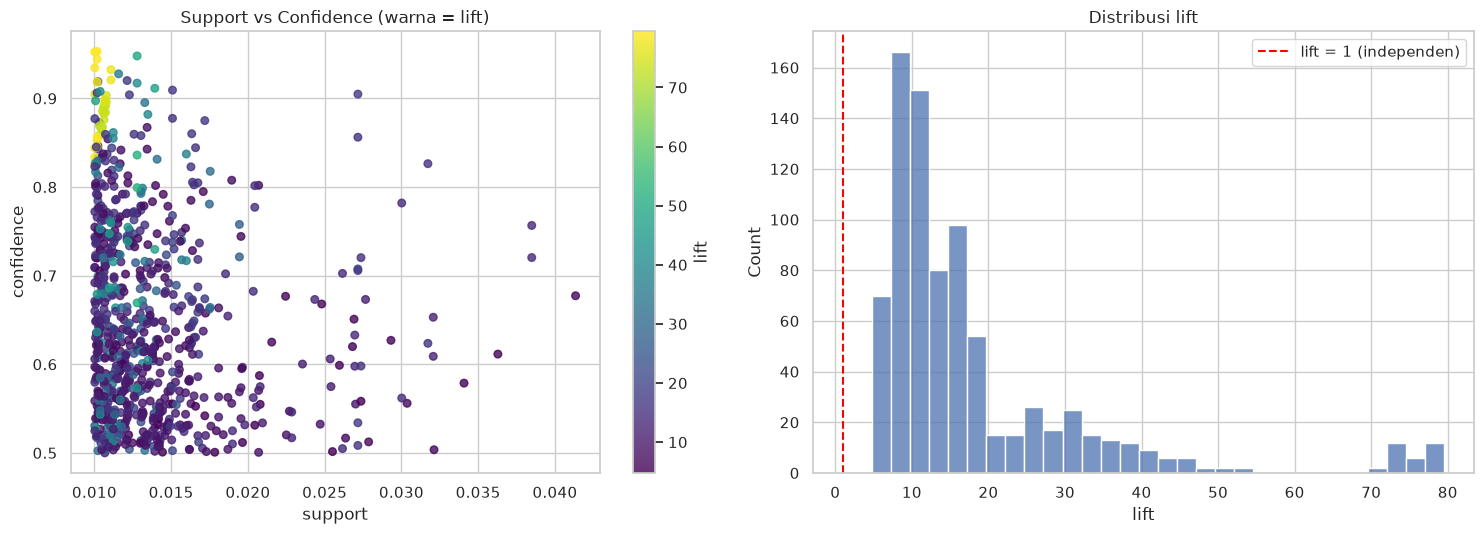

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sc = ax[0].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=30, alpha=0.8)
ax[0].set_xlabel("support"); ax[0].set_ylabel("confidence"); ax[0].set_title("Support vs Confidence (warna = lift)")
plt.colorbar(sc, ax=ax[0], label="lift")
sns.histplot(rules["lift"], bins=30, ax=ax[1], color="#4C72B0")
ax[1].axvline(1, color="red", ls="--", label="lift = 1 (independen)")
ax[1].set_title("Distribusi lift"); ax[1].legend()
plt.tight_layout(); plt.show()

### Tiga aturan terbaik berdasarkan lift

Peringkat lift mentah didominasi satu keluarga produk (*herb marker*: Thyme, Rosemary, Parsley, Mint, Basil) yang muncul puluhan kali dalam kombinasi berbeda, dan setiap aturan `A → B` punya kembaran `B → A` dengan lift sama. Agar tiga aturan yang dipilih informatif dan tidak redundan, dipakai tiga langkah:
1. hanya aturan satu item → satu item (mudah diinterpretasi),
2. satu arah per pasangan (lift tertinggi, lalu confidence tertinggi),
3. tiap aturan terpilih berasal dari keluarga produk berbeda (kata pertama nama produk berbeda).

In [17]:
r = rules[(rules["antecedents"].map(len) == 1) & (rules["consequents"].map(len) == 1)].copy()
r["key"] = r.apply(lambda x: frozenset(x["antecedents"] | x["consequents"]), axis=1)
r = r.sort_values(["lift", "confidence"], ascending=False).drop_duplicates("key")

def keluarga(row):
    return {next(iter(x)).split()[0] for x in (row["antecedents"], row["consequents"])}

terpilih, dipakai = [], set()
for _, row in r.iterrows():
    fam = keluarga(row)
    if fam & dipakai:
        continue
    terpilih.append(row); dipakai |= fam
    if len(terpilih) == 3:
        break

top3 = pd.DataFrame(terpilih)
top3["antecedents"] = top3["antecedents"].map(fmt)
top3["consequents"] = top3["consequents"].map(fmt)
top3 = top3[["antecedents", "consequents", "support", "confidence", "lift"]].reset_index(drop=True)
top3.index += 1
top3

,antecedents,consequents,support,confidence,lift
1,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011075,0.920833,77.532613
2,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.013931,0.911475,47.738824
3,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.010975,0.747440,46.756021


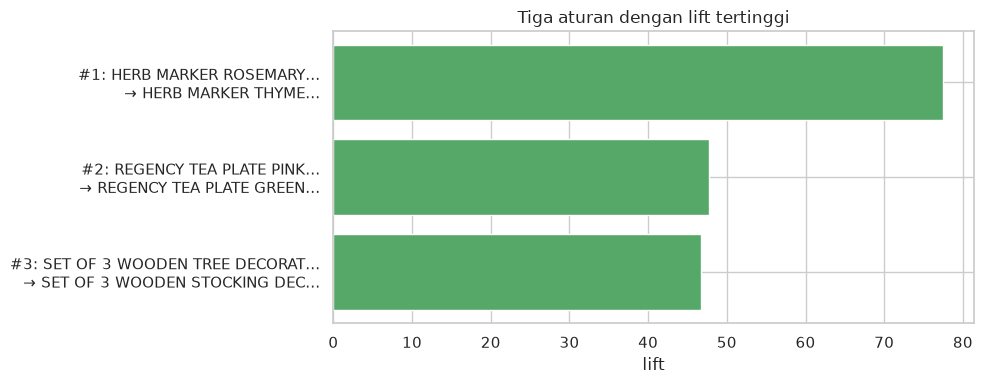

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
lbl = [f"#{i}: {a[:28]}…\n→ {c[:28]}…" for i, (a, c) in enumerate(zip(top3["antecedents"], top3["consequents"]), 1)]
ax.barh(lbl[::-1], top3["lift"][::-1], color="#55A868")
ax.set_xlabel("lift"); ax.set_title("Tiga aturan dengan lift tertinggi")
plt.tight_layout(); plt.show()

### Interpretasi bisnis

Semua aturan memiliki lift jauh di atas 1 (minimum 4,78; median 12,6), artinya produk-produk tersebut dibeli bersamaan jauh lebih sering daripada kebetulan.

| # | Aturan | Support | Confidence | Lift |
|---|--------|---------|-----------|------|
| 1 | HERB MARKER ROSEMARY → HERB MARKER THYME | 1,11% (≈221 invoice) | 92,1% | 77,5 |
| 2 | REGENCY TEA PLATE PINK → REGENCY TEA PLATE GREEN | 1,39% (≈278 invoice) | 91,1% | 47,7 |
| 3 | SET OF 3 WOODEN TREE DECORATIONS → SET OF 3 WOODEN STOCKING DECORATION | 1,10% (≈219 invoice) | 74,7% | 46,8 |

1. **Herb marker Rosemary → Thyme.** Dari setiap 100 invoice berisi penanda tanaman Rosemary, sekitar 92 juga berisi Thyme, dan peluangnya 77 kali lebih tinggi daripada pembelian acak. Pelanggan membeli *seluruh set* herb marker (Basil, Mint, Parsley, Rosemary, Thyme), bukan satuan. Implikasi: jual sebagai bundle/paket lengkap dan tampilkan semua varian berdampingan.
2. **Regency tea plate Pink → Green.** Pelanggan melengkapi koleksi warna dalam satu seri produk (lini Regency juga berasosiasi dengan teapot, sugar bowl, milk jug). Implikasi: rekomendasi "lengkapi koleksi" di halaman produk dan penawaran set tea party.
3. **Wooden tree decorations → wooden stocking decorations.** Pola musiman Natal: pembeli dekorasi pohon juga mengambil dekorasi lain dari seri sama (sekitar 75%). Implikasi: tata letak/bundle bertema Natal dan stok dikoordinasikan antarproduk seri tersebut menjelang musim.

**Catatan:** support tiap aturan hanya ≈1%, jadi pola ini berlaku pada segmen pembeli tertentu (kemungkinan besar pelanggan grosir/reseller yang membeli seri produk lengkap), bukan seluruh transaksi. Lift sangat tinggi pada itemset ber-support kecil juga bisa membesar karena produk komponennya sendiri jarang.


## 6. Kesimpulan

- **Data:** dari 541.909 baris / 25.900 invoice, pembersihan (Description kosong, invoice batal "C", Quantity ≤ 0, dan item non-produk seperti POSTAGE) menyisakan **528.368 baris, 19.955 invoice, 4.057 produk unik**. Matriks basket sangat jarang (kepadatan ≈0,64%), rata-rata ≈26 produk unik per invoice (median 15).
- **Algoritma:** FP-Growth dengan `min_support = 0,01` dan `min_confidence = 0,5` menghasilkan **1.820 frequent itemset** dan **816 aturan** — jumlah yang wajar, sehingga parameter tidak diubah. Menaikkan support ke 0,02 menyisakan hanya 60 aturan; menurunkannya ke 0,005 menghasilkan ≈19.600 aturan.
- **Pola dominan:** aturan dengan lift tertinggi berasal dari **produk satu seri/varian** (herb marker, Regency tea set, dekorasi kayu Natal, polkadot cup/bowl, jam jar warna). Pelanggan cenderung membeli produk pelengkap dalam satu lini, bukan lintas kategori.
- **Implikasi bisnis:** bundling set lengkap, rekomendasi "lengkapi koleksi", penataan produk seri berdampingan, dan perencanaan stok bersama untuk produk satu seri (terutama musiman).
- **Keterbatasan:** support rendah (≈1–4%) dan basis pelanggan campuran (ritel + grosir) berarti aturan berlaku pada segmen tertentu; lift yang sangat tinggi perlu dibaca bersama support agar tidak berlebihan menafsirkan.
